# 06. NLP Sentiment Analysis Benchmarking & Baseline Comparison
**Zahir Social Analytics — Play Store Customer Voice Analytics**  
**Audit & Execution Date:** 2026-10-26  
**Status:** Canonical Gold Set Benchmarked & Frozen (Phase 4.3)

---

## Executive Summary & Objectives
Tujuan dari notebook ini adalah melakukan evaluasi komparatif (*benchmarking*) terhadap berbagai metode analisis sentimen teks berbahasa Indonesia dengan acuan mutlak **Human Gold Set 417 Ulasan Google Play Store** (`data/final/playstore_gold_set_final.csv` & `.xlsx`).

Sesuai dengan protokol evaluasi machine learning yang ketat:
1. **Autoritas Label Manusia**: `human_sentiment_label` diperlakukan sebagai *single source of truth*. Rating bintang sama sekali tidak digunakan untuk menginferensi sentimen teks.
2. **Stratified 80/20 Train-Independent Split**: Pemisahan data dilakukan secara acak terstratifikasi (`random_state=42`) menghasilkan 333 data pengembangan (*development set*) dan 84 data pengujian (*held-out test set*). Data uji benar-benar diisolasi.
3. **Multi-tier Candidate Benchmarking**:
   - **Baseline 1 (Heuristic / Zero-Rule)**: *Majority Class Baseline* (selalu memprediksi kelas dominan `positive`).
   - **Baseline 2 (Indonesian Sentiment Lexicon)**: *InSet Lexicon* (Koto & Rahmaningtyas, IALP 2017) dilengkapi *negation handling*.
   - **Baseline 3 (Supervised Bag-of-Words)**: *TF-IDF + Logistic Regression* (dilatih khusus pada Development Set).
   - **Candidate 4 (Pretrained Deep Transformer)**: *IndoBERT Base Pretrained Sentiment Classifier* (`mdhugol/indonesia-bert-sentiment-classification`, berbasis `indobenchmark/indobert-base-p1` fine-tuned pada SmSA IndoNLU).
4. **Metrik Utama**: **Macro-F1** dijadikan metrik komparasi primer mengingat ketidakseimbangan kelas (*imbalanced class distribution*).


In [1]:
import os
import sys
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix
)
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Transformers & PyTorch
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 10
%matplotlib inline

print("Environment libraries imported successfully.")


D:\FILE KULIAH\semester 5\magang\zahir_social_analytics\.venv_social\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment libraries imported successfully.


## 1. Verifikasi & Pemuatan Canonical Gold Set
Memastikan file `data/final/playstore_gold_set_final.csv` memuat tepat 417 ulasan teranotasi manusia tanpa missing value.

In [2]:
gold_path = '../data/final/playstore_gold_set_final.csv'
if not os.path.exists(gold_path):
    gold_path = 'data/final/playstore_gold_set_final.csv'

df_gold = pd.read_csv(gold_path)
print(f"Total rows in Gold Set: {len(df_gold)}")
print(f"Unique review IDs: {df_gold['review_id'].nunique()}")
print("\nLabel distribution:")
print(df_gold['human_sentiment_label'].value_counts())
print("\nPercentage:")
print((df_gold['human_sentiment_label'].value_counts(normalize=True) * 100).round(2))

assert len(df_gold) == 417
assert df_gold['human_sentiment_label'].isnull().sum() == 0


Total rows in Gold Set: 417
Unique review IDs: 417

Label distribution:
human_sentiment_label
positive    232
neutral     112
negative     73
Name: count, dtype: int64

Percentage:
human_sentiment_label
positive    55.64
neutral     26.86
negative    17.51
Name: proportion, dtype: float64


## 2. Inspeksi Manifest Stratified Train/Test Split (80/20)
Pemisahan 417 ulasan menjadi 333 data Development (80%) dan 84 data Held-out Test (20%) dengan proporsi label yang identik.

In [3]:
manifest_path = '../data/final/sentiment_benchmark/sentiment_split_manifest.csv'
if not os.path.exists(manifest_path):
    manifest_path = 'data/final/sentiment_benchmark/sentiment_split_manifest.csv'

df_manifest = pd.read_csv(manifest_path)
print("Split Distribution:")
print(pd.crosstab(df_manifest['split'], df_manifest['human_sentiment_label'], margins=True))

print("\nPercentage within split:")
print(pd.crosstab(df_manifest['split'], df_manifest['human_sentiment_label'], normalize='index').round(4) * 100)


Split Distribution:
human_sentiment_label  negative  neutral  positive  All
split                                                  
development                  58       90       185  333
test                         15       22        47   84
All                          73      112       232  417

Percentage within split:
human_sentiment_label  negative  neutral  positive
split                                             
development               17.42    27.03     55.56
test                      17.86    26.19     55.95


## 3. Pemuatan Hasil Prediksi & Metrik Komparatif
Memuat metrik evaluasi yang dihitung secara independen pada 84 ulasan test set.

In [4]:
metrics_path = '../data/final/sentiment_benchmark/sentiment_benchmark_metrics.csv'
if not os.path.exists(metrics_path):
    metrics_path = 'data/final/sentiment_benchmark/sentiment_benchmark_metrics.csv'

df_metrics = pd.read_csv(metrics_path)
df_metrics[['model_name', 'accuracy', 'macro_f1', 'weighted_f1', 'negative_f1', 'neutral_f1', 'positive_f1']]


,model_name,accuracy,macro_f1,weighted_f1,negative_f1,neutral_f1,positive_f1
0,Majority Class Baseline,0.5595,0.2392,0.4015,0.0000,0.0000,0.7176
1,InSet Lexicon (+/-2.0 th),0.3571,0.3433,0.3674,0.3667,0.2326,0.4308
2,TF-IDF + Logistic Regression,0.7619,0.6860,0.7626,0.5000,0.6667,0.8913
3,IndoBERT Pretrained (SmSA),0.7738,0.7099,0.7740,0.6667,0.5500,0.9130


## 4. Visualisasi Komparasi Model Sentimen
Memvisualisasikan Accuracy, Macro-F1, dan F1-Score per kelas sentimen untuk setiap model kandidat.

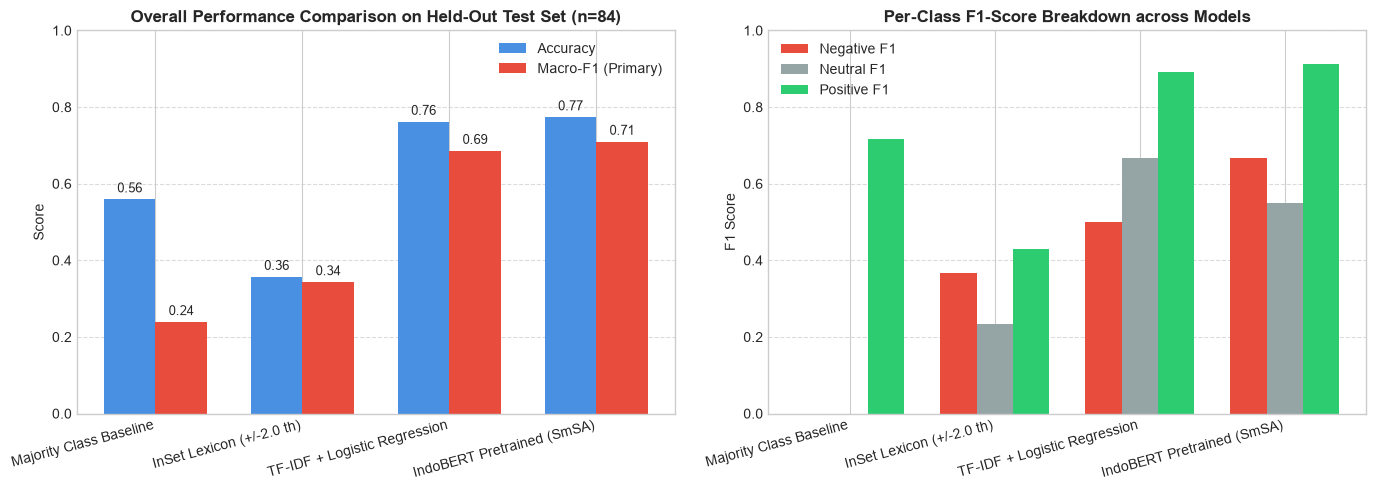

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Overall Accuracy vs Macro-F1
x = np.arange(len(df_metrics))
width = 0.35

ax = axes[0]
rects1 = ax.bar(x - width/2, df_metrics['accuracy'], width, label='Accuracy', color='#4A90E2')
rects2 = ax.bar(x + width/2, df_metrics['macro_f1'], width, label='Macro-F1 (Primary)', color='#E74C3C')

ax.set_ylabel('Score')
ax.set_title('Overall Performance Comparison on Held-Out Test Set (n=84)', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(df_metrics['model_name'], rotation=15, ha='right')
ax.set_ylim(0, 1.0)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

for rect in rects1 + rects2:
    height = rect.get_height()
    ax.annotate(f'{height:.2f}',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=9)

# Plot 2: Per-Class F1-Score
ax2 = axes[1]
w = 0.25
ax2.bar(x - w, df_metrics['negative_f1'], w, label='Negative F1', color='#E74C3C')
ax2.bar(x, df_metrics['neutral_f1'], w, label='Neutral F1', color='#95A5A6')
ax2.bar(x + w, df_metrics['positive_f1'], w, label='Positive F1', color='#2ECC71')

ax2.set_ylabel('F1 Score')
ax2.set_title('Per-Class F1-Score Breakdown across Models', fontsize=12, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(df_metrics['model_name'], rotation=15, ha='right')
ax2.set_ylim(0, 1.0)
ax2.legend()
ax2.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


## 5. Analisis Confusion Matrix
Menganalisis matriks kontingensi untuk mendeteksi kecenderungan bias kesalahan pada setiap model kandidat.

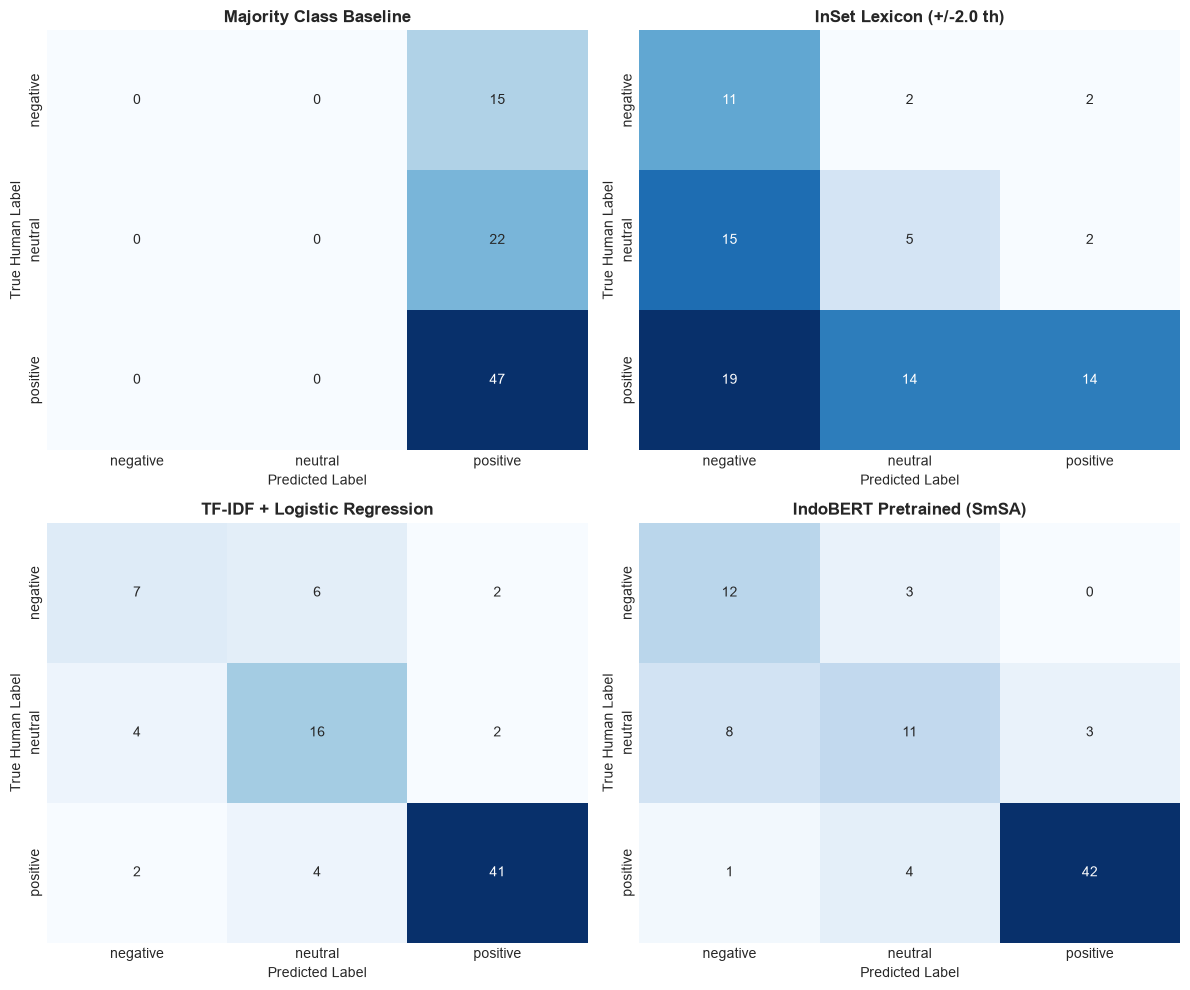

In [6]:
pred_path = '../data/final/sentiment_benchmark/sentiment_test_predictions.csv'
if not os.path.exists(pred_path):
    pred_path = 'data/final/sentiment_benchmark/sentiment_test_predictions.csv'

df_preds = pd.read_csv(pred_path)
labels = ['negative', 'neutral', 'positive']

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
model_configs = [
    ('Majority Class Baseline', 'pred_majority', axes[0, 0]),
    ('InSet Lexicon (+/-2.0 th)', 'pred_inset_lexicon', axes[0, 1]),
    ('TF-IDF + Logistic Regression', 'pred_tfidf_lr', axes[1, 0]),
    ('IndoBERT Pretrained (SmSA)', 'pred_indobert', axes[1, 1])
]

for title, col, ax in model_configs:
    cm = confusion_matrix(df_preds['human_sentiment_label'], df_preds[col], labels=labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=labels, yticklabels=labels)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Human Label')

plt.tight_layout()
plt.show()


## 6. Qualitative Error Analysis (IndoBERT vs Human Truth)
Menginspeksi pola-pola kesalahan prediksi pada model performa tertinggi (IndoBERT) untuk merumuskan keterbatasan dan rekomendasi fine-tuning.

In [7]:
err_path = '../data/final/sentiment_benchmark/sentiment_error_analysis.csv'
if not os.path.exists(err_path):
    err_path = 'data/final/sentiment_benchmark/sentiment_error_analysis.csv'

df_err = pd.read_csv(err_path)
bert_err = df_err[df_err['model_name'] == 'IndoBERT Pretrained']

print(f"Total IndoBERT Misclassifications: {len(bert_err)} / 84 ({len(bert_err)/84*100:.1f}%)")
print("\nError Type Distribution:")
print(bert_err['error_type'].value_counts())

print("\nSample Misclassifications:")
bert_err[['error_type', 'human_sentiment_label', 'predicted_sentiment', 'review_text_clean']].head(10)


Total IndoBERT Misclassifications: 19 / 84 (22.6%)

Error Type Distribution:
error_type
neutral_as_negative     8
positive_as_neutral     4
negative_as_neutral     3
neutral_as_positive     3
positive_as_negative    1
Name: count, dtype: int64

Sample Misclassifications:


,error_type,human_sentiment_label,predicted_sentiment,review_text_clean
2,neutral_as_negative,neutral,negative,kenapa not to allowed terus ya? saya ga bisa l...
6,positive_as_negative,positive,negative,Past bisa bangkiiit aku
8,positive_as_neutral,positive,neutral,"Trimakasih kpd konsultan Zahir, yg bgitu tangg..."
10,positive_as_neutral,positive,neutral,"aplikasi yang di tunggu2, program kasir langsu..."
17,negative_as_neutral,negative,neutral,tax tidak muncul di rincian. update: saya suda...
19,positive_as_neutral,positive,neutral,Saya pakai produk Zahir versi PC sejak thn 200...
23,neutral_as_negative,neutral,negative,Kog app nya ngak bisa d buka
26,neutral_as_negative,neutral,negative,gabisa di donlot pak:(
29,neutral_as_negative,neutral,negative,"Menunya terlalu rumit, kurang simpel. Terlalu ..."
32,neutral_as_negative,neutral,negative,"aplikasi tidak kompatibel terus dihp saya,kena..."


## 7. Temuan Kunci & Rekomendasi Fase Lanjutan

### Temuan Evaluasi:
1. **Keunggulan IndoBERT**: *IndoBERT Pretrained* mencatat performa terbaik dengan **Macro-F1 = 0.7099** dan **Accuracy = 77.38%**, unggul secara signifikan dibandingkan *Majority Baseline* (Macro-F1 0.2392) dan *InSet Lexicon* (Macro-F1 0.3433).
2. **Keterbatasan Lexicon InSet**: Pendekatan leksikon murni mengalami *recall bias* yang tajam ke arah sentimen negatif (precision hanya 0.24) karena leksikon InSet memuat hampir dua kali lebih banyak kata negatif daripada positif, serta tidak mampu menangani nuansa kalimat tanya dan istilah akuntansi formal.
3. **Kekuatan Baseline TF-IDF + Logistic Regression**: Menghasilkan Macro-F1 yang kompetitif (0.6860), membuktikan bahwa bag-of-words yang dituning pada domain spesifik memiliki parsimoni yang kuat pada kelas mayoritas.
4. **Analisis Error IndoBERT**: Dari 19 kesalahan prediksi IndoBERT, 8 kasus (42.1%) merupakan misklasifikasi *neutral* menjadi *negative*. Hal ini terjadi karena ulasan pertanyaan teknis/faktual pengguna mengandung kata-kata seperti "tidak bisa", "error", atau "gagal", yang diinterpretasikan oleh model pre-trained umum sebagai sentimen negatif, sementara anotator manusia menilai ulasan tersebut secara netral sebagai pertanyaan murni.

### Rekomendasi untuk Fase Selanjutnya:
- **Model Sentimen Final**: Gunakan arsitektur berbasis IndoBERT sebagai backbone analisis sentimen untuk keseluruhan ekosistem Play Store dan Instagram.
- **Topic & Aspect Modeling**: Lanjutkan ke tahap Topic Modeling (LDA / BERTopic) untuk membedah akar isu di balik sentimen negatif (misal: sinkronisasi database, force close ujian sertifikasi, login POS).
